In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *
from utils.Loss import *


# onebyone

In [2]:
def calculate_batch_mae(preds, targets, fs=30):
    
    mae_sum = 0.0
    valid_count = 0
    
    # GPU 텐서를 CPU 넘파이 배열로 변
    
    # 2. FFT 기반 HR 추출
    pred_hr, _, _ = hr_fft(preds, fs)
    gt_hr, _, _ = hr_fft(targets, fs)
    
    mae = abs(pred_hr - gt_hr)
            
    return mae

def z_norm_per_sample(x):
    # x: (B, T)
    mean = x.mean(dim=-1, keepdim=True)   # (B, 1)
    std  = x.std(dim=-1, keepdim=True)    # (B, 1)
    return (x - mean) / (std + 1e-8)      # per-sample


모델 로드 완료
['/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier/final_dataset_A002_20250609.h5']


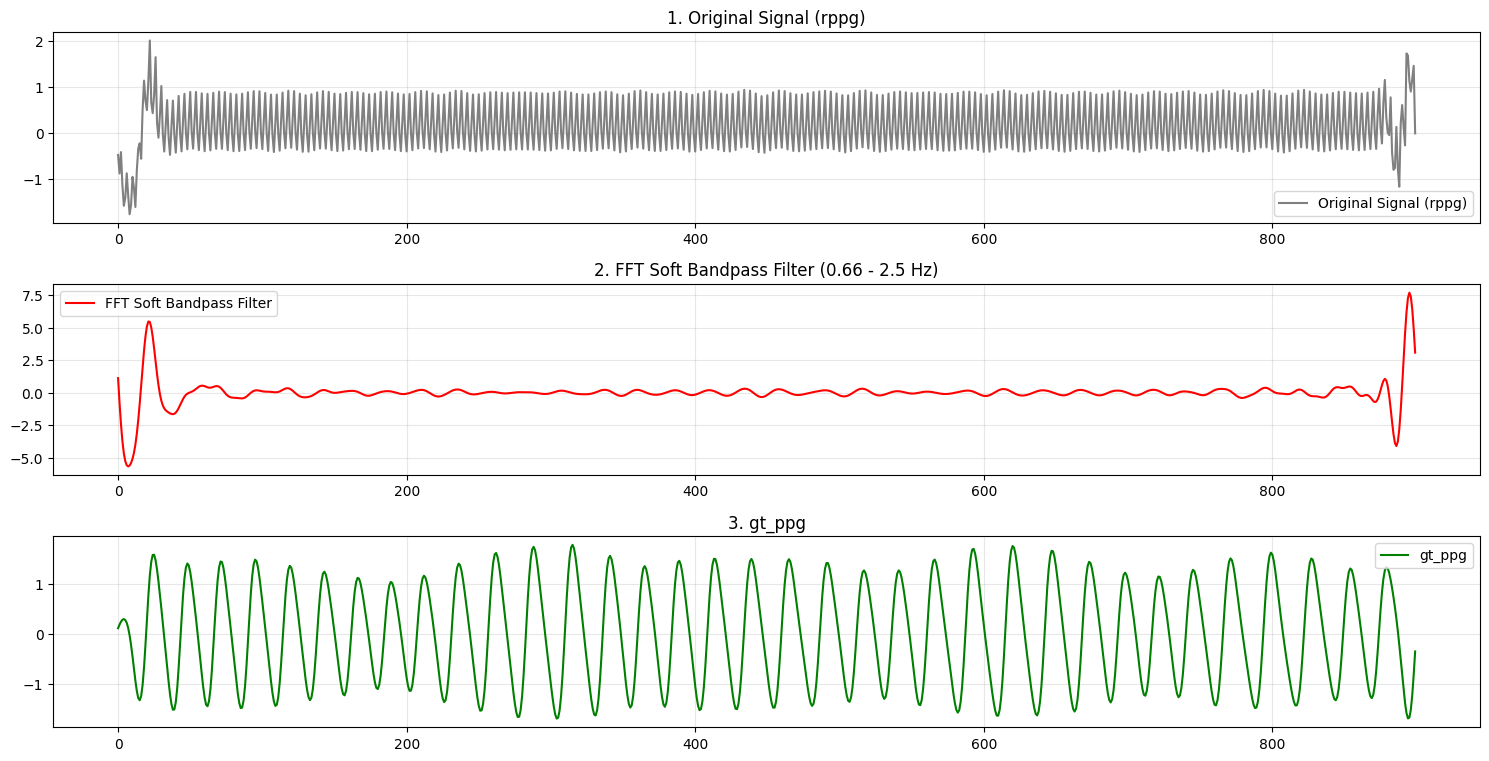

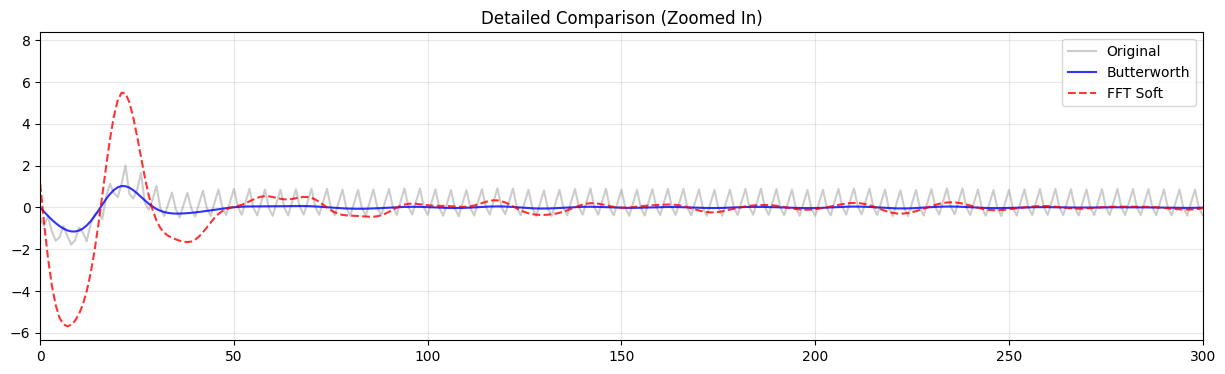

soft fft : 0.0 butter : 0.0
전체 통째로 계산한 Loss: 0.9904
6조각으로 나누어 평균낸 Loss: 0.9010
각 조각별 Loss: [0.7383, 0.6592, 0.9077, 0.7114, 1.1033, 1.286]


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.signal import butter, filtfilt

# ===== 설정 및 모델 로드 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/900franewithregis_13out_and_znorm/bandpassbeforelosscompute_physformerloss_withoutce_bstartwith0.05/0.00030000000000000003_epoch:20_MAE: 9.54.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_driving_withoutoutlier_len300_gtsubjectznorm'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'

model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 및 추론 =====

all_files = [os.path.join(data_dir, u) for u in sorted(os.listdir(data_dir)) if u.endswith('.h5') ]
valid_files = all_files[1:2]
print(valid_files)
valid_dataset = rPPGDataset(valid_files)

input_vid , gt_ppg, _ = valid_dataset[0]
input_vid = input_vid.unsqueeze(0)

# 💡 1. 데이터를 모델과 같은 디바이스(GPU)로 이동
input_vid = input_vid.to(device)

# 💡 2. 기울기 계산 방지 (추론 모드)
with torch.no_grad():
    rppg , _, _, _ = model(input_vid)

# 💡 3. SciPy 필터 및 시각화를 위해 CPU로 내리고 NumPy 1D 배열로 변환
rppg_np = rppg.cpu().numpy().flatten()


# ===== 1. 필터 함수 정의 =====
def butter_bandpass_filter(data, lowcut = 0.66, highcut= 2.5 , fs = 30 , order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    y = filtfilt(b, a, data)
    return y

def bandpass_fft_soft(signal, fs=30, low_hz=0.66, high_hz=2.5, steepness=50.0):
    is_numpy = isinstance(signal, np.ndarray)
    if is_numpy:
        signal = torch.tensor(signal, dtype=torch.float32)
        
    N = signal.shape[-1]
    freqs = torch.fft.rfftfreq(N, d=1.0/fs).to(signal.device)
    fft_signal = torch.fft.rfft(signal)
    mask = torch.sigmoid(steepness * (freqs - low_hz)) * \
           torch.sigmoid(steepness * (high_hz - freqs))
    fft_filtered = fft_signal * mask
    filtered = torch.fft.irfft(fft_filtered, n=N)
    
    if is_numpy:
        return filtered.cpu().numpy()
    return filtered

ncor = Neg_Pearson()

def get_cor_sliced (rppg, ppg, window_num) :
    signal_size = rppg.shape[-1]
    window_size = signal_size // window_num
    cor_list = []
    for i in range(0, window_num) :
        rppg_sliced = rppg[i*window_size : (i+1) * window_size].unsqueeze(0)
        ppg_sliced = ppg[i*window_size : (i+1) * window_size].unsqueeze(0)
        cor_list.append(ncor(rppg_sliced, ppg_sliced).item())
    ncor_mean = sum(cor_list) / window_num
    ncor_whole = ncor(rppg.unsqueeze(0), ppg.unsqueeze(0)).item()

    return cor_list, ncor_mean, ncor_whole

# ===== 3. 필터 적용 =====
# 이제 rppg_np는 numpy 배열이므로 에러 없이 잘 작동합니다.
butter_filtered = butter_bandpass_filter(rppg_np)
fft_soft_filtered = bandpass_fft_soft(rppg_np)
fft_soft_filtered = (fft_soft_filtered - np.mean(fft_soft_filtered)) / np.std(fft_soft_filtered)
# ===== 4. 시각화 (Plot) =====
plt.figure(figsize=(15, 10))

plt.subplot(4, 1, 1)
plt.plot(rppg_np, color='gray', label='Original Signal (rppg)')
plt.title('1. Original Signal (rppg)')
plt.legend()
plt.grid(True, alpha=0.3)

# plt.subplot(4, 1, 2)
# plt.plot(butter_filtered, color='blue', label='Butterworth Filtered')
# plt.title('2. Butterworth Bandpass Filter (0.66 - 2.5 Hz)')
# plt.legend()
# plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 2)
plt.plot(fft_soft_filtered, color='red', label='FFT Soft Bandpass Filter')
plt.title('2. FFT Soft Bandpass Filter (0.66 - 2.5 Hz)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 3)
plt.plot(gt_ppg, color='green', label='gt_ppg')
plt.title('3. gt_ppg')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ===== 5. 겹쳐서 확대 비교해보기 =====
plt.figure(figsize=(15, 4))
# 💡 4. 아래 orig_sig 를 rppg_np로 변경
plt.plot(rppg_np, color='gray', alpha=0.4, label='Original')
plt.plot(butter_filtered, color='blue', alpha=0.8, label='Butterworth')
plt.plot(fft_soft_filtered, color='red', alpha=0.8, linestyle='--', label='FFT Soft')
plt.title('Detailed Comparison (Zoomed In)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 300) 
plt.show()

print(f'soft fft : {calculate_batch_mae(gt_ppg, fft_soft_filtered)} butter : {calculate_batch_mae(gt_ppg, butter_filtered)}')


rppg_tensor = torch.tensor(fft_soft_filtered.copy(), dtype=torch.float32)


cor_list, ncor_mean, ncor_whole = get_cor_sliced(rppg_tensor, gt_ppg, window_num=6)

print(f"전체 통째로 계산한 Loss: {ncor_whole:.4f}")
print(f"6조각으로 나누어 평균낸 Loss: {ncor_mean:.4f}")
print(f"각 조각별 Loss: {[round(c, 4) for c in cor_list]}")

# all

In [4]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/parameter_save/900franewithregis_13out_and_znorm/bandpassbeforelosscompute_physformerloss_withoutce_bstartwith0.05/0.00030000000000000003_epoch:21_MAE: 11.51.pth'
data_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# ===== 모델 로드 =====
model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[15:]
valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=24, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []
all_preds_with_filter = []
all_cor_list = []
fil_cor_list = []

with torch.no_grad():
    for inputs, targets, hr in valid_loader:
        inputs  = inputs.to(device)
        outputs, _, _, _ = model(inputs)

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

all_preds_with_filter = bandpass_fft_soft(all_preds, fs=30, low_hz=0.66, high_hz=2.5)

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

Los = Neg_Pearson()

# ===== Plot =====
n_plot = 25  # 몇 개 샘플 볼지
fig, axes = plt.subplots(5, 5, figsize=(40, 60))
axes = axes.flatten()

for i in range(n_plot):
    # 코드가 길어지는 것을 방지하기 위해 변수에 할당
    gt_sig = all_targets[i]
    pred_sig_filt =  all_preds_with_filter[i] 
    pred_sig_orig = all_preds[i]
    # 신호 그리기
    axes[i].plot(gt_sig, label='GT', color='blue', alpha=0.7)
    axes[i].plot(pred_sig_filt / (np.max(pred_sig_filt) +1e-8) , label='Predicted with filter', color='red', alpha=0.7)
    #axes[i].plot(pred_sig_orig,   label='Predicted', color='green',   alpha=0.7)
    axes[i].set_ylim(-3,3)
    
    # --- 💡 평균값 계산 및 수평선 그리기 추가 💡 ---
    gt_mean = np.mean(gt_sig)
    pred_mean = np.mean(pred_sig_filt)
    
    axes[i].axhline(y=gt_mean, color='darkblue', linestyle='--', alpha=0.8, 
                    label=f'GT Mean ({gt_mean:.2f})')
    axes[i].axhline(y=pred_mean, color='darkred', linestyle='--', alpha=0.8, 
                    label=f'Pred Mean ({pred_mean:.2f})')
    # ---------------------------------------------


    cor_all_win = Los(torch.tensor(pred_sig_orig.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(), dtype=torch.float32).unsqueeze(0))
    cor_after_filter  = Los(torch.tensor(pred_sig_filt.copy(), dtype=torch.float32).unsqueeze(0), 
                    torch.tensor(gt_sig.copy(),   dtype=torch.float32).unsqueeze(0))
    all_cor_list.append(cor_all_win)
    fil_cor_list.append(cor_after_filter)
    axes[i].set_title(f'|before bandpass: {cor_all_win.item():.4f} | after bandpass: {cor_after_filter.item():.4f}')

    # 범례가 많아지므로 폰트 크기를 살짝 줄이거나 위치를 조정하는 것도 좋습니다.
    axes[i].legend(loc='upper right', fontsize='small') 
    axes[i].set_xlabel('Frame')


plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, 'slice_ncor_nonormalize_timedomain_test15_lowestmaeepoch_sclaeup'), dpi= 100)
plt.show()
print(f'all : {(sum(all_cor_list) / len(all_cor_list))} sliced : {sum(fil_cor_list) / len(fil_cor_list)}')


모델 로드 완료


OutOfMemoryError: CUDA out of memory. Tried to allocate 5.27 GiB. GPU 0 has a total capacity of 23.68 GiB of which 676.69 MiB is free. Process 3297253 has 22.20 GiB memory in use. Including non-PyTorch memory, this process has 828.00 MiB memory in use. Of the allocated memory 358.54 MiB is allocated by PyTorch, and 229.46 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [56]:
from scipy.fft import fft

n_plot = len(all_preds)
fig, axes = plt.subplots(n_plot, 3, figsize=(16, 4*n_plot))
mae_all = []
mae_clipped = []
for i in range(n_plot):
    pred_sig = all_preds_with_filter[i] * np.hanning(len(all_preds_with_filter[i]))
    gt_sig   = all_targets[i] * np.hanning(len(all_targets[i]))
    pred_sig_orig = all_preds[i] * np.hanning(len(all_preds[i]))

    hr_pred_a, psd_preda, x_hr_preda = hr_fft(pred_sig_orig, fs=30)
    hr_pred, psd_pred, x_hr_pred = hr_fft(pred_sig , fs=30)
    hr_gt,   psd_gt,   x_hr_gt   = hr_fft(gt_sig,   fs=30)
    

    # GT PSD
    axes[i, 0].plot(x_hr_gt, psd_gt, color='blue', alpha=0.8)
    axes[i, 0].axvline(hr_gt,   color='blue',  linestyle='--', label=f'GT HR: {hr_gt:.1f} BPM')
    axes[i, 0].set_xlim(0, 150)
    axes[i, 0].set_title(f'Sample {i} - GT')
    axes[i, 0].set_xlabel('HR (BPM)')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].legend()

    # Pred PSD
    axes[i, 1].plot(x_hr_pred, psd_pred, color='red', alpha=0.8)
    axes[i, 1].axvline(hr_pred, color='red',   linestyle='--', label=f'Pred HR: {hr_pred:.1f} BPM')
    axes[i, 1].set_xlim(0, 150)
    axes[i, 1].set_title(f'Sample {i} - Predicted')
    axes[i, 1].set_xlabel('HR (BPM)')
    axes[i, 1].set_ylabel('Amplitude')
    axes[i, 1].legend()

    # axes[i,2].plot(x_hr_preda, psd_preda, color='green', alpha=0.8 )
    # axes[i, 2].set_xlim(0, 1800)
    # axes[i, 2].axvline(hr_pred_a, color='green',   linestyle='--', label=f'Preda HR: {hr_pred_a:.1f} BPM')
    # axes[i, 2].legend()

    mae_all.append(np.abs(hr_pred_a - hr_gt))
    mae_clipped.append(np.abs(hr_pred - hr_gt))
plt.tight_layout()

plt.show()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_frequencydomain'), dpi= 100)
print("저장완료: fft_comparison.png")
print(f'all : {sum(mae_all) / len(mae_all)}, sliced :: {sum(mae_clipped) / len(mae_clipped)}')

저장완료: fft_comparison.png
all : 1.6229508196721316, sliced :: 1.5245901639344273


<Figure size 640x480 with 0 Axes>